# 5. Recreate the FlowMapper.org example maps from CSV

The FlowMapper repository shares maps made on FlowMapper.org (`flowmapper_*.png`) with the
project files that produced them. Here each map is **rebuilt from the raw CSV and GeoJSON files**,
with the settings written out as a *recipe*: the settings that differ from FlowMapper.org's
defaults. A recipe shows which panel options make the map, and you can copy and adapt it.

Each map is then drawn in its high-contrast version (TAF flows, pale regions, nodes sized by flow
and drawn on top) and zoomed to where the flows are. The legend and title are kept outside the
zoom extent. To see a recipe exactly as FlowMapper.org draws it, use
`show(p, contrast=False)` on the project before `figure_ground()`. Notebook 01 compares the saved
projects with the web site's pictures.

### Setup

Imports, the data folder, and a few helpers used below: `figure_ground()` (the high-contrast look),
`size_nodes_by_total_flow()`, `show()` / `map_image()` / `show_grid()` (draw maps) and
`compare_settings()` (draw the same map with different settings side by side).

In [1]:
%matplotlib inline
import io
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import flowmapper_org as fm

# Example data of the FlowMapper GitHub repository (folder "Data"): FLOWMAPPER_DATA, else the
# repository these notebooks live in (python/notebooks -> ../../Data), else a local clone.
_candidates = [os.environ.get("FLOWMAPPER_DATA"), Path.cwd().parent.parent / "Data", r"D:\GitHub\flowmapper\Data"]
DATA = next((Path(c) for c in _candidates if c and Path(c).is_dir()), None)
assert DATA is not None, ("FlowMapper example data not found: clone https://github.com/geo-social/flowmapper "
                          "and set FLOWMAPPER_DATA to its Data folder")
OUT = Path("output")
OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("flowmapper.org", fm.__version__, "- mirrors FlowMapper.org", fm.FLOWMAPPER_WEB_VERSION)

# ---------------------------------------------------------------------------------------------
# The look used in these notebooks: figure-ground contrast.
#   * flows are the figure: Tapered Fading Arc (TAF), dark colour ramps, full opacity;
#   * regions are the ground: their colours are kept but drawn pale (35 % opacity);
#   * nodes are drawn on top of the flows, dark grey with a white outline.
# figure_ground() only sets ordinary FlowMapper settings, so the projects still open on
# FlowMapper.org. CONTRAST holds two Python-only drawing options (never saved in the file):
#   flow_contrast - raises the opacity of the fading arcs, so small flows stay visible;
#   flow_halo     - a thin white casing that separates flows from the regions below.
# ---------------------------------------------------------------------------------------------
CONTRAST = dict(flow_contrast=0.5, flow_halo=("#ffffff", 0.7))

# Zoom extents (west, south, east, north), a drawing option: render(..., extent=...).
# The legend and title are kept outside the extent.
LOWER48 = (-125, 24, -66.5, 49.5)
EUROPE = (-12, 34, 58, 68)


def us_extent(p):
    """LOWER48 when most of the project's nodes are in the contiguous U.S., else None.

    Every U.S. map in these notebooks is zoomed to the lower 48 (not Alaska and Hawaii):
    map_image() / show() use this whenever no extent is given."""
    ns = p.node_settings
    xf, yf = ns.get("X"), ns.get("Y")
    if p.nodes is None or xf not in p.nodes.columns or yf not in p.nodes.columns:
        return None
    x = pd.to_numeric(p.nodes[xf], errors="coerce")
    y = pd.to_numeric(p.nodes[yf], errors="coerce")
    ok = x.notna() & y.notna()
    if not ok.any():
        return None
    w, s, e, n = LOWER48
    inside = (x[ok].between(w, e) & y[ok].between(s, n)).mean()
    return LOWER48 if inside >= 0.8 else None

# Dark ramps (light end, dark end). The light end is a mid-tone, so the smallest flows
# are still clearly visible; a ColorBrewer ramp such as "Blues" starts almost white.
FLOW_RAMPS = {
    "navy":   ("#4a6fa5", "#0b1f4b"),
    "orange": ("#f16913", "#7f2704"),
    "purple": ("#807dba", "#3f007d"),
    "teal":   ("#3a9e8f", "#00332b"),
}


def figure_ground(p, flows="navy", region_opacity=35, node_color="#3d3d3d"):
    """Pale regions, dark prominent flows, nodes on top (ordinary FlowMapper settings)."""
    lo, hi = FLOW_RAMPS[flows] if flows in FLOW_RAMPS else flows
    p.flow_settings.update(flowStyleName="TAF", clrScheme="Custom", minCustomColor=lo, maxCustomColor=hi,
                           fillOpacity=100)
    p.region_settings.update(fillOpacity=region_opacity, strokeColor="#9e9e9e", strokeWidth=0.4)
    p.node_settings.update(clrScheme="Custom", minCustomColor=node_color, maxCustomColor=node_color,
                           noAttrFillColor=node_color, strokeColor="#ffffff", strokeWidth=0.8, fillOpacity=100)
    p.view_settings["drawingOrder"] = "nodes"          # nodes on top of flows
    return p


def size_nodes_by_total_flow(p, rmin=2, rmax=16, title="Total flow (in + out)", measure="__fm:grossflow"):
    """Circle size = gross flow (in-flow + out-flow), calculated from the flows.

    measure="__fm:inflow" sizes by flow received instead: better when one origin sends
    everything (refugees from one country), where the origin's total would dwarf the rest."""
    p.node_settings.update(ifMapAttribute=True, volume=measure, cfMethod="Proportional",
                           radiusMin=rmin, radiusMax=rmax, legendTitle=title)
    return p


_seen_notices = set()


def map_image(project, contrast=True, **render_options):
    """Draw a project at its own size and return the picture as an array.

    contrast=True adds the CONTRAST drawing options; False draws exactly as FlowMapper.org.
    Legends, title and scale bar are sized in screen pixels, so maps are drawn on their own
    and then tiled, rather than squeezed into small subplot axes."""
    opts = {**(CONTRAST if contrast else {}), **render_options}
    if "extent" not in opts and us_extent(project) is not None:
        opts["extent"] = LOWER48         # U.S. data: the lower 48, never Alaska and Hawaii
    r = project.render(**opts)       # with an extent, the title and legend are kept off the extent
    for n in r.notices:                     # FlowMapper's messages, each shown once
        if n not in _seen_notices:
            _seen_notices.add(n)
            print("notice:", n)
    buf = io.BytesIO()
    r.fig.savefig(buf, format="png")
    buf.seek(0)
    return plt.imread(buf)


def show(project, width=1000, height=700, contrast=True, **render_options):
    """Draw one map in the notebook."""
    show_grid([map_image(project, contrast, width=width, height=height, **render_options)], ncols=1,
              width=width / 70)


def show_grid(images, titles=None, ncols=3, width=22):
    """Tile pictures (arrays from map_image or plt.imread) in a grid."""
    nrows = -(-len(images) // ncols)
    h, w = images[0].shape[:2]
    fig, axes = plt.subplots(nrows, ncols, figsize=(width, width / ncols * h / w * nrows + 0.4 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, im, t in zip(axes.flat, images, titles or [""] * len(images)):
        ax.imshow(im)
        ax.set_title(t)
    plt.tight_layout()
    plt.show()


def compare_settings(base, variants, ncols=3, width=900, height=600, **render_options):
    """Draw copies of `base`, each with some settings changed.

    variants = {"label": {"flow_settings": {...}, "node_settings": {...}, ...}, ...}"""
    images = []
    for label, change in variants.items():
        q = base.copy()
        for block, values in change.items():
            getattr(q, block).update(values)
        images.append(map_image(q, width=width, height=height, **render_options))
    show_grid(images, list(variants), ncols=ncols)

flowmapper.org 0.3.0 - mirrors FlowMapper.org 2.1


In [2]:
def apply_recipe(p, recipe):
    """Set the settings of a recipe: {"flow_settings": {...}, "node_settings": {...}, ...}."""
    for block, values in recipe.items():
        getattr(p, block).update(values)
    return p


def final_map(p, extent, width=1100, height=800, **render_options):
    """The high-contrast map, zoomed to `extent`; legend and title stay outside the extent."""
    show(p, width=width, height=height, extent=extent, **render_options)

## Refugees from Ukraine, end of 2022

Files: `Refugees/Ukraine/nodes_countries.csv`, `flows_ukraine_refugees_2022.csv`,
`regions_europe.geojson`. The node file is also the region attribute table.

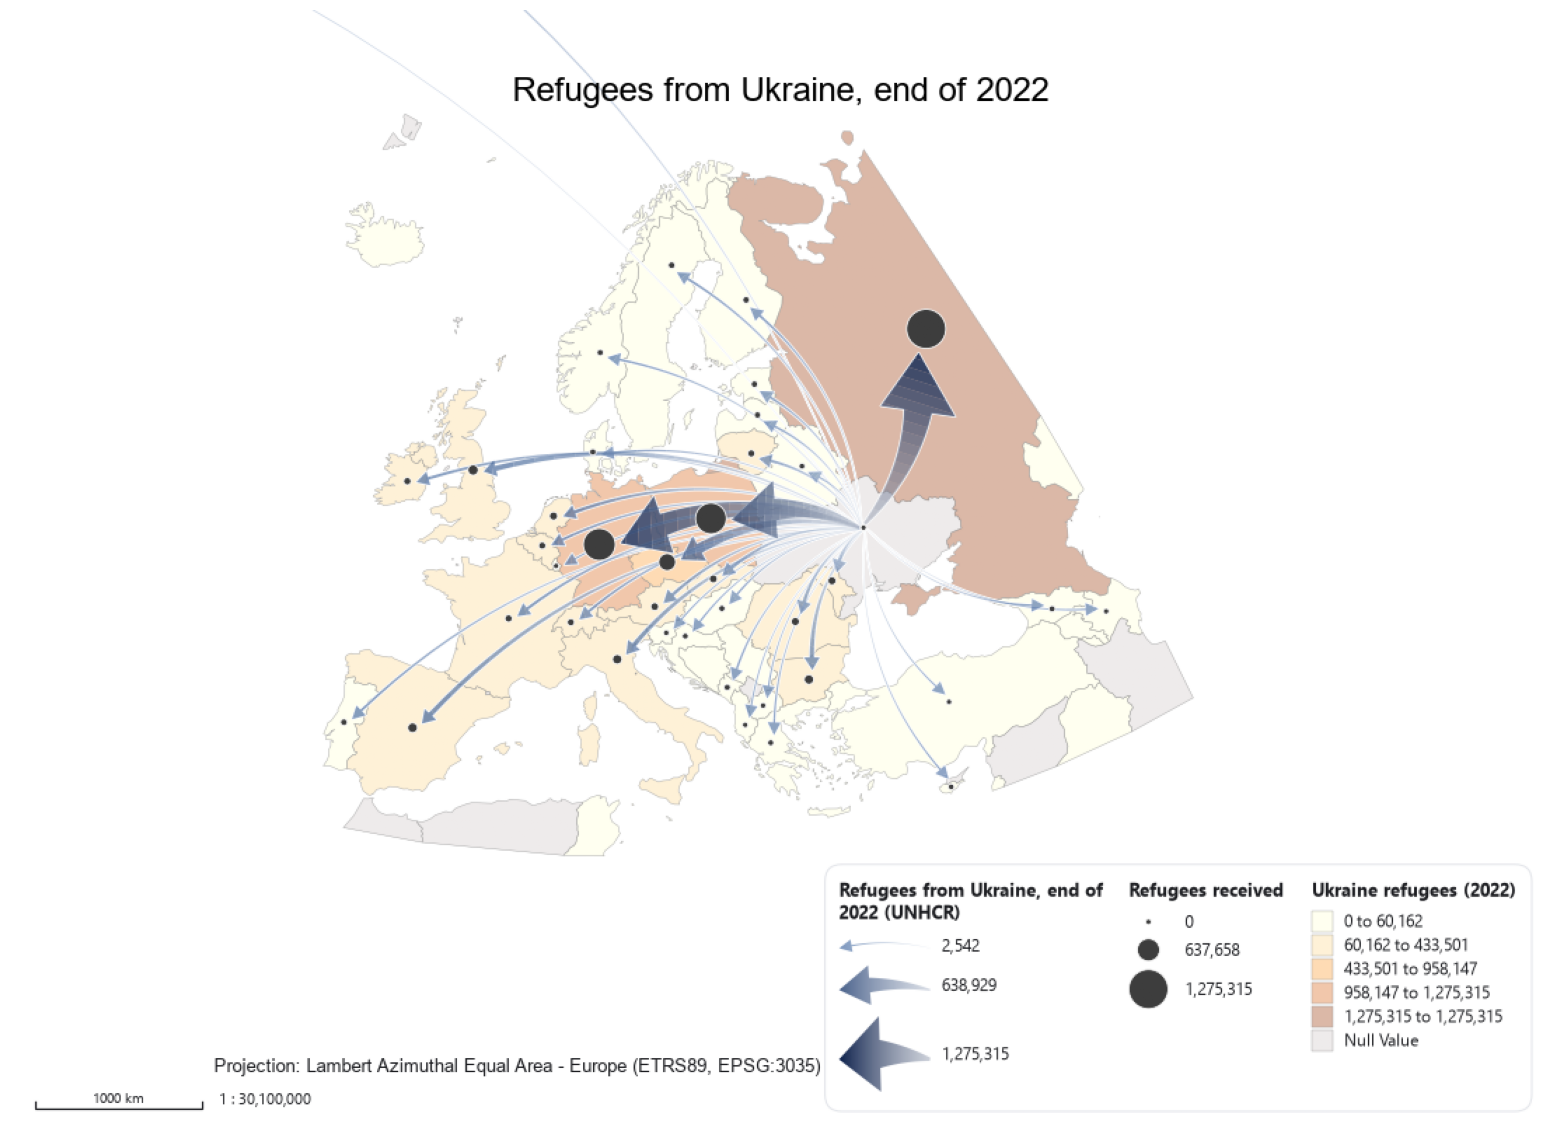

In [3]:
U = DATA / "Refugees" / "Ukraine"
ukr = fm.Project.from_data(U / "nodes_countries.csv", U / "flows_ukraine_refugees_2022.csv",
                           regions=U / "regions_europe.geojson", region_table=U / "nodes_countries.csv",
                           name="Ukraine refugees 2022")
ukraine_recipe = {
    "basemap_settings": {"projection": "laeaEurope", "ifAddTitle": True, "title": "Refugees from Ukraine, end of 2022",
                         "titleSize": 24, "ifAddProjectionLabel": True},
    "region_join": {"geoId": "iso3", "CSVId": "iso3", "value": "refugees_2022"},
    "region_settings": {"ifMapRegionAttribute": True, "cfMethod": "NaturalBreak", "clrScheme": "Oranges",
                        "fillOpacity": 85, "strokeColor": "#ffffff", "strokeWidth": 0.4,
                        "legendTitle": "Ukraine refugees (2022)", "fillColorNoAttr": "#e0e0e0"},
    "node_settings": {"id": "iso3", "X": "lon", "Y": "lat", "ifMapAttribute": False,
                      "noAttrFillColor": "#333333", "noAttrRadius": 3, "strokeWidth": 0},
    "flow_settings": {"origin": "origin", "destination": "destination", "volume": "refugees",
                      "flowStyleName": "TAF", "clrScheme": "Custom", "minCustomColor": "#1d4f7a",
                      "maxCustomColor": "#08203a", "fillOpacity": 90, "numTopFlows": 40, "widthMin": 1, "widthMax": 20,
                      "strokeWidth": 0.3, "legendTitle": "Refugees from Ukraine, end of 2022 (UNHCR)"},
}
apply_recipe(ukr, ukraine_recipe)

# high-contrast version: pale regions, navy flows, nodes sized by refugees received
# (in-flow: with one origin, total flow would make Ukraine itself the only large circle)
ukr_hc = figure_ground(ukr.copy(), flows="navy")
ukr_hc.region_settings["clrScheme"] = "YlOrBr"
size_nodes_by_total_flow(ukr_hc, rmin=2, rmax=14, title="Refugees received", measure="__fm:inflow")
final_map(ukr_hc, EUROPE)

## Hurricane Katrina: out-migration 2005–06

Files: `DisasterMigration/Katrina/nodes_counties.csv`, `flows_katrina_out_2005_06.csv`,
`regions_us_states.geojson`, `regions_states_katrina_totals.csv`.

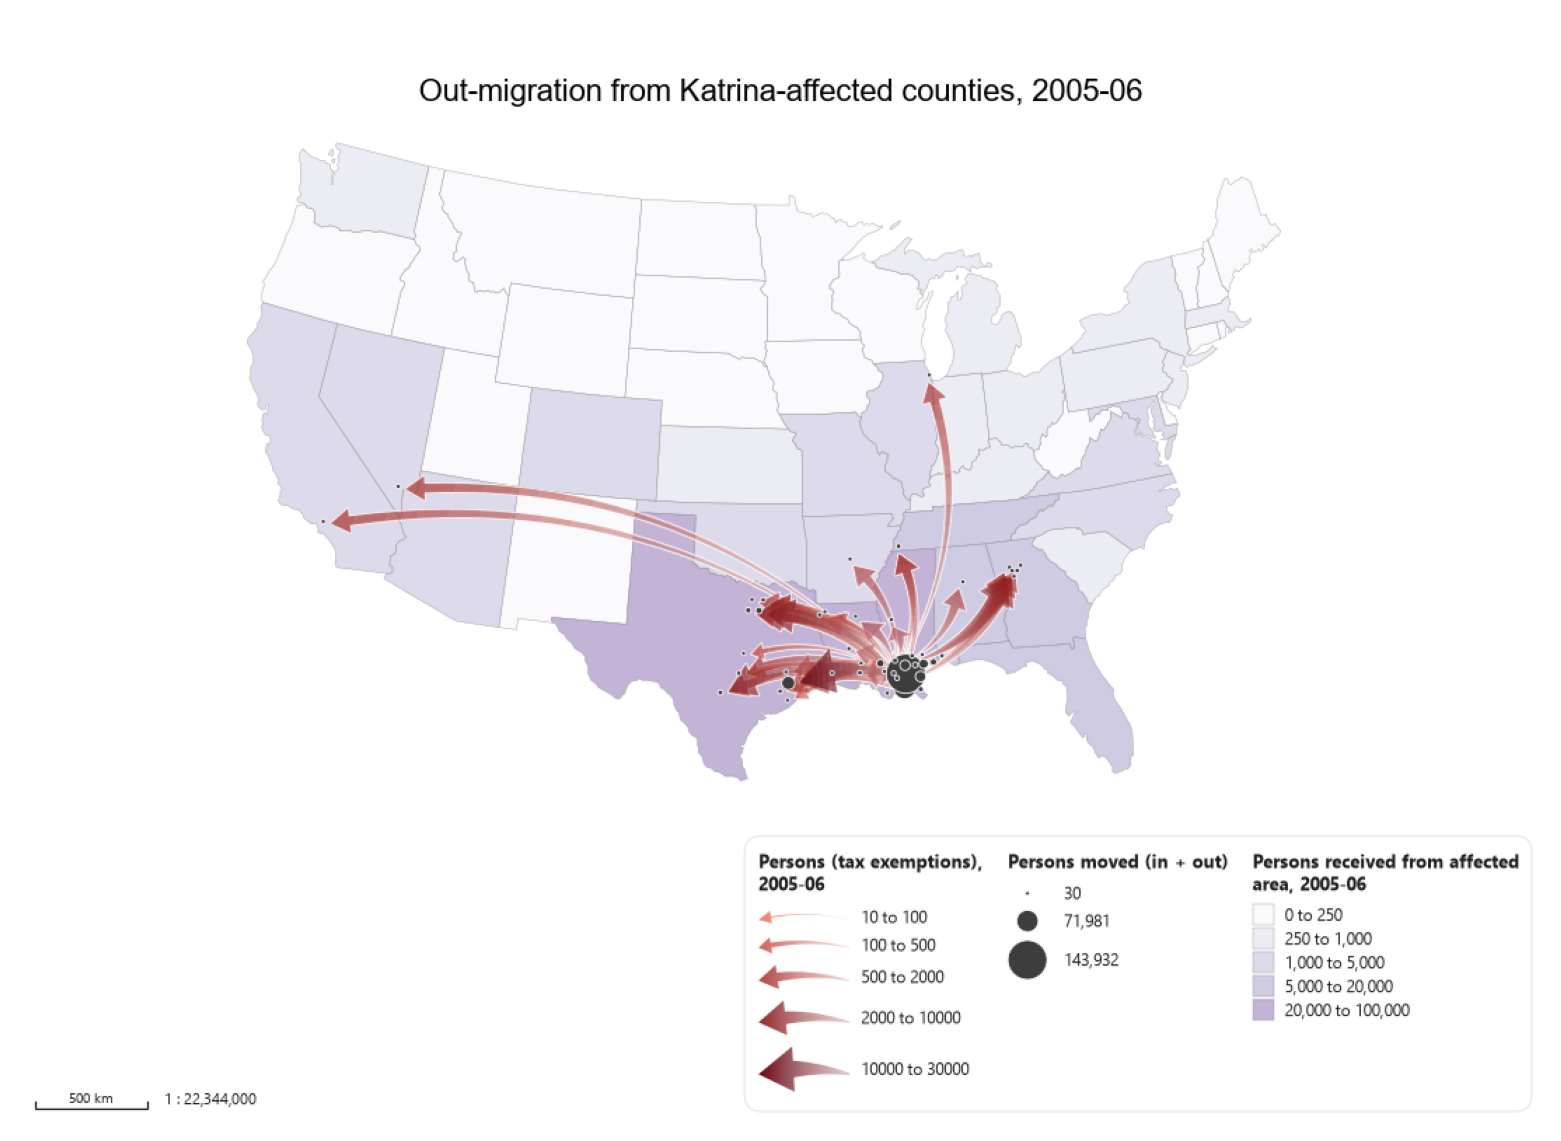

In [4]:
K = DATA / "DisasterMigration" / "Katrina"
kat = fm.Project.from_data(K / "nodes_counties.csv", K / "flows_katrina_out_2005_06.csv",
                           regions=K / "regions_us_states.geojson",
                           region_table=K / "regions_states_katrina_totals.csv",
                           name="Out-migration from Katrina-affected counties, 2005-06")
katrina_recipe = {
    "basemap_settings": {"projection": "abEqAreaUS", "ifAddTitle": True,
                         "title": "Out-migration from Katrina-affected counties, 2005-06", "titleSize": 22},
    "region_join": {"geoId": "name", "CSVId": "name", "value": "persons_from_katrina_area_2005_06"},
    "region_settings": {"ifMapRegionAttribute": True, "cfMethod": "ManualBreak", "clrScheme": "Purples",
                        "breakInput": "0 250 1000 5000 20000 100000", "fillOpacity": 75, "strokeColor": "#ffffff",
                        "legendTitle": "Persons received from affected area, 2005-06"},
    "node_settings": {"id": "fips", "X": "lon", "Y": "lat", "ifMapAttribute": False,
                      "noAttrFillColor": "#333333", "noAttrRadius": 2, "strokeWidth": 0},
    "flow_settings": {"origin": "origin", "destination": "destination", "volume": "persons",
                      "flowStyleName": "TAF", "cfMethod": "ManualBreak", "breakInput": "10 100 500 2000 10000 30000",
                      "clrScheme": "Custom", "minCustomColor": "#f4a259", "maxCustomColor": "#9b2226",
                      "fillOpacity": 90, "numTopFlows": 150, "widthMin": 1, "widthMax": 16, "strokeWidth": 0.3,
                      "legendTitle": "Persons (tax exemptions), 2005-06"},
}
apply_recipe(kat, katrina_recipe)

kat_hc = figure_ground(kat.copy(), flows=("#e34a33", "#67000d"))
kat_hc.flow_settings.update(numTopFlows=80, widthMax=12)
size_nodes_by_total_flow(kat_hc, rmin=1.5, rmax=14, title="Persons moved (in + out)")
final_map(kat_hc, LOWER48)

## Refugees from Syria, end of 2024

Same layout as Ukraine; the regions show refugees per 1,000 residents with manual breaks.

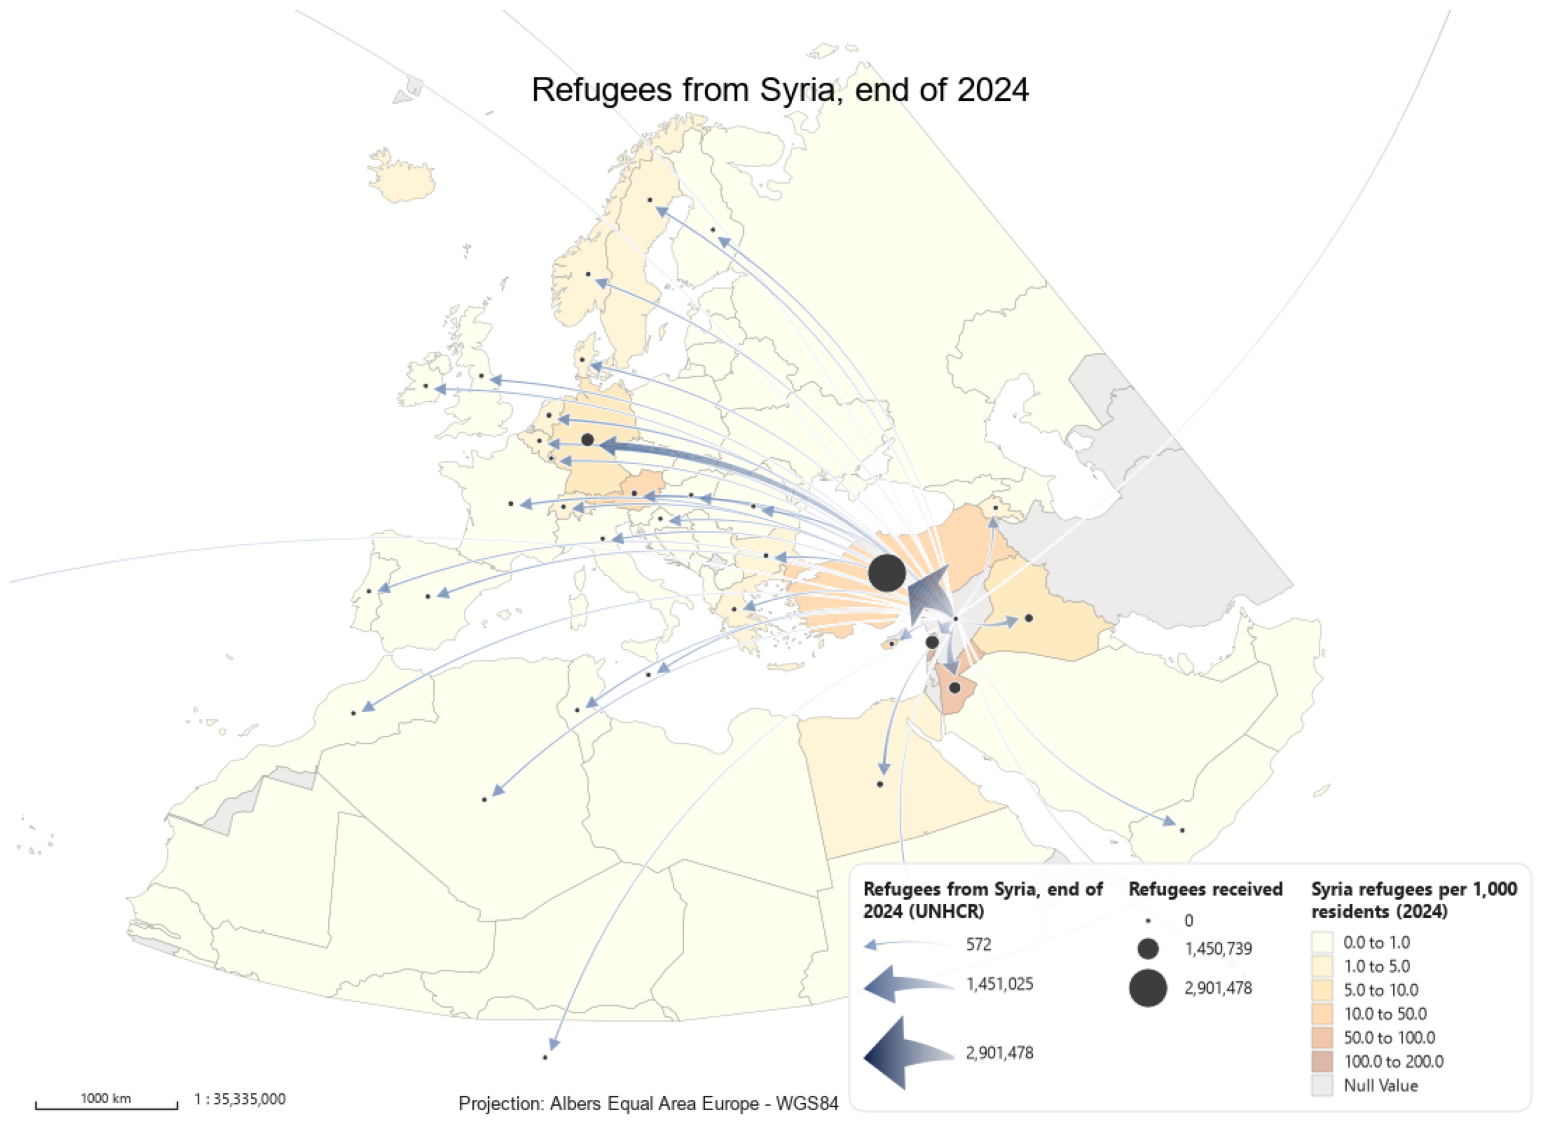

In [5]:
S = DATA / "Refugees" / "Syria"
syr = fm.Project.from_data(S / "nodes_countries.csv", S / "flows_syria_refugees_2024.csv",
                           regions=S / "regions_europe_mena.geojson", region_table=S / "nodes_countries.csv",
                           name="Syria refugees 2024")
syria_recipe = {
    **ukraine_recipe,
    "basemap_settings": {"projection": "abEqAreaEu", "ifAddTitle": True, "title": "Refugees from Syria, end of 2024",
                         "titleSize": 24, "ifAddProjectionLabel": True},
    "region_join": {"geoId": "iso3", "CSVId": "iso3", "value": "refugees_per_1000_pop_2024"},
    "region_settings": {**ukraine_recipe["region_settings"], "cfMethod": "ManualBreak", "clsNum": 6,
                        "breakInput": "0 1 5 10 50 100 200", "decimalPlaces": 1,
                        "legendTitle": "Syria refugees per 1,000 residents (2024)"},
    "flow_settings": {**ukraine_recipe["flow_settings"], "legendTitle": "Refugees from Syria, end of 2024 (UNHCR)"},
}
apply_recipe(syr, syria_recipe)

syr_hc = figure_ground(syr.copy(), flows="navy")
syr_hc.region_settings["clrScheme"] = "YlOrBr"
size_nodes_by_total_flow(syr_hc, rmin=2, rmax=14, title="Refugees received", measure="__fm:inflow")
final_map(syr_hc, (-12, 24, 60, 64))      # Europe, Turkey and the Middle East

## Banana trade in South America, 2019

This map uses the Tear Drop style; the high-contrast version uses TAF.

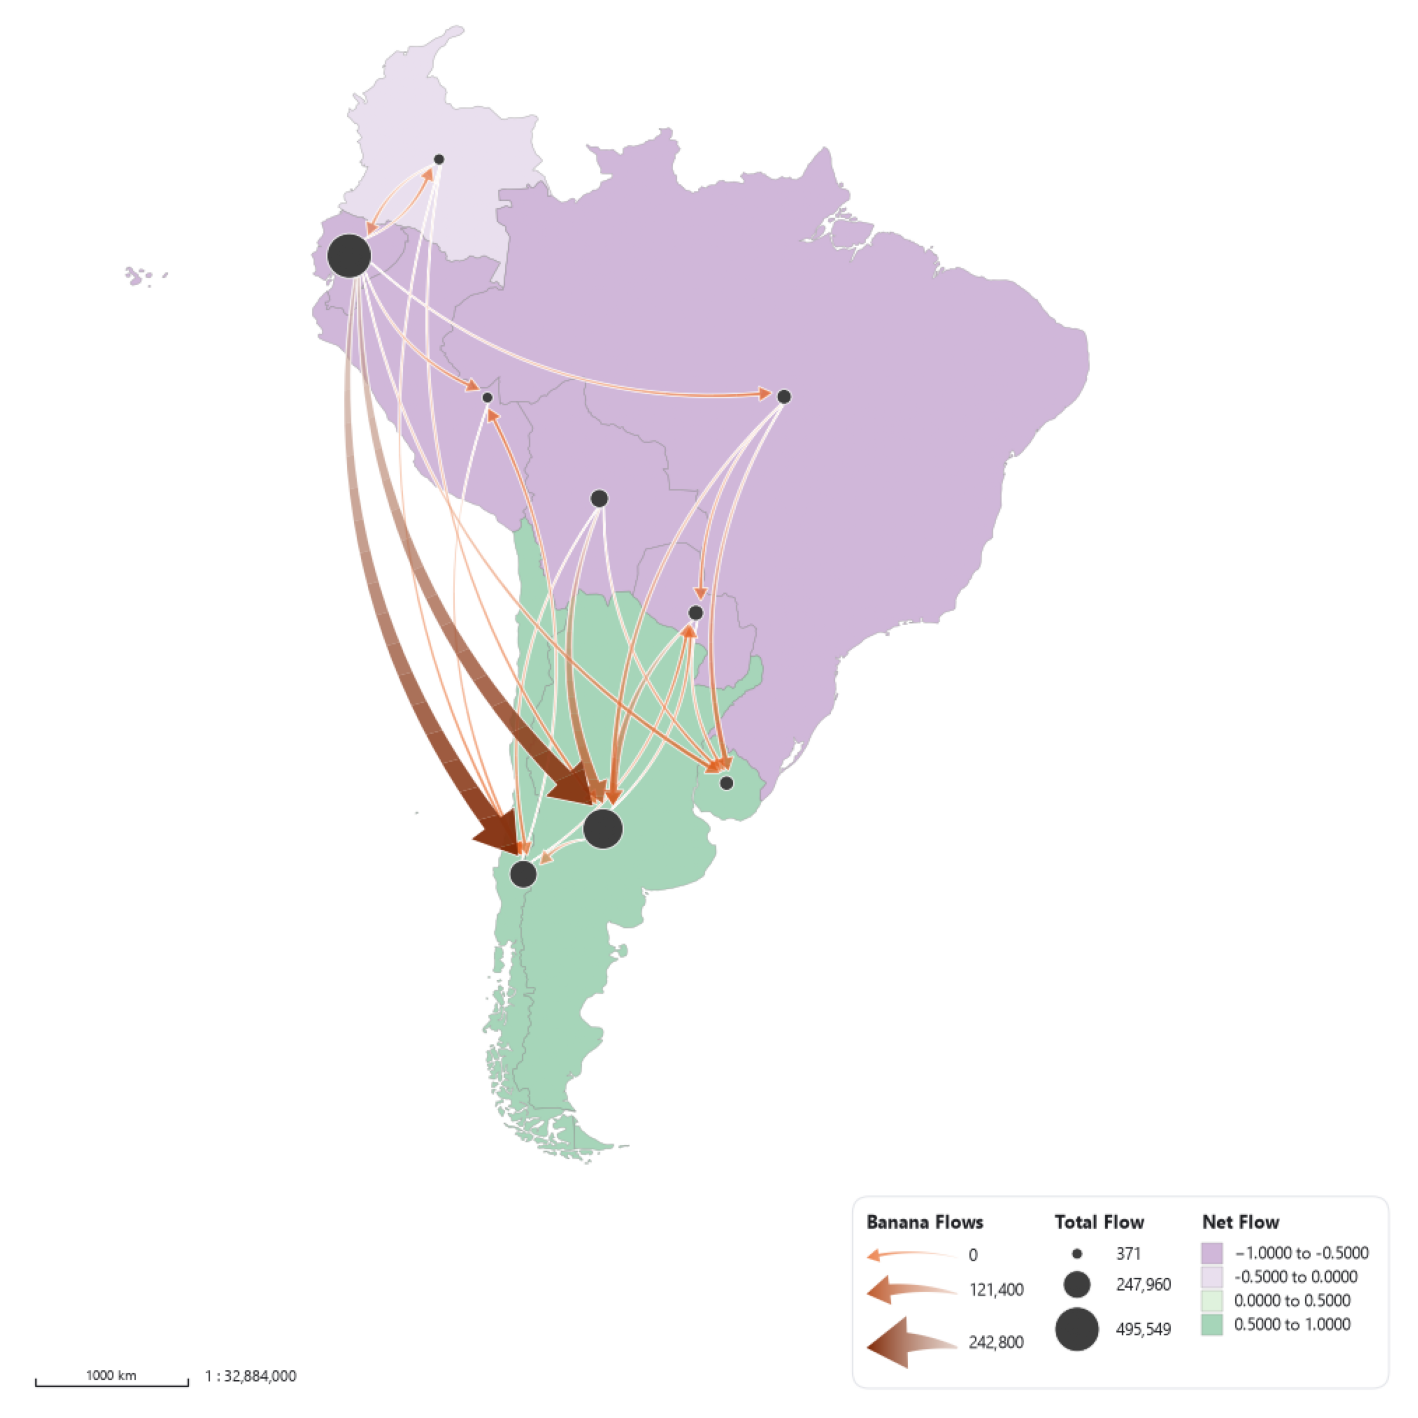

In [6]:
Bn = DATA / "Bananas"
ban = fm.Project.from_data(Bn / "nodes_bananas_SA_2019.csv", Bn / "flows_bananas_SA_2019.csv",
                           regions=Bn / "regions_SA.geojson", region_table=Bn / "regions_bananas_SA_2019.csv",
                           name="Bananas 2019")
bananas_recipe = {
    "basemap_settings": {"projection": "abEqAreaSthAm"},
    "region_join": {"geoId": "CntryCode", "CSVId": "Country_ID", "value": "Net_Flow_Ratio"},
    "region_settings": {"ifMapRegionAttribute": True, "cfMethod": "ManualBreak", "clrScheme": "PRGn",
                        "breakInput": "-1 -0.5 0 0.5 1", "decimalPlaces": 4, "fillOpacity": 60, "legendTitle": "Net Flow"},
    "node_settings": {"id": "Country_ID", "X": "X", "Y": "Y", "ifMapAttribute": True, "volume": "Total_Flow",
                      "radiusMin": 5, "radiusMax": 16, "legendTitle": "Total Flow"},
    "flow_settings": {"origin": "From_Country_ID", "destination": "To Country_ID", "volume": "Value",
                      "flowStyleName": "tearDrop", "clrScheme": "Custom", "minCustomColor": "#82a9f2",
                      "maxCustomColor": "#003985", "clsNum": 4, "numTopFlows": 22, "widthMin": 7, "widthMax": 25,
                      "strokeColor": "#464444", "legendTitle": "Banana Flows"},
}
apply_recipe(ban, bananas_recipe)

ban_hc = figure_ground(ban.copy(), flows=("#e6550d", "#7f2704"))
ban_hc.flow_settings.update(widthMin=2, widthMax=14)
size_nodes_by_total_flow(ban_hc, rmin=4, rmax=16, title="Total Flow")
final_map(ban_hc, (-82, -56, -34, 13), width=1000, height=1000)     # South America

## Family-tree migration, 1887–1924

Curve Half Arrow (CHA) flows over a net-migration choropleth.

notice: 154 flows use node IDs that are not in the node file (or have no coordinates), e.g. 143, 102, 108, 115, 149, .... They are not drawn.


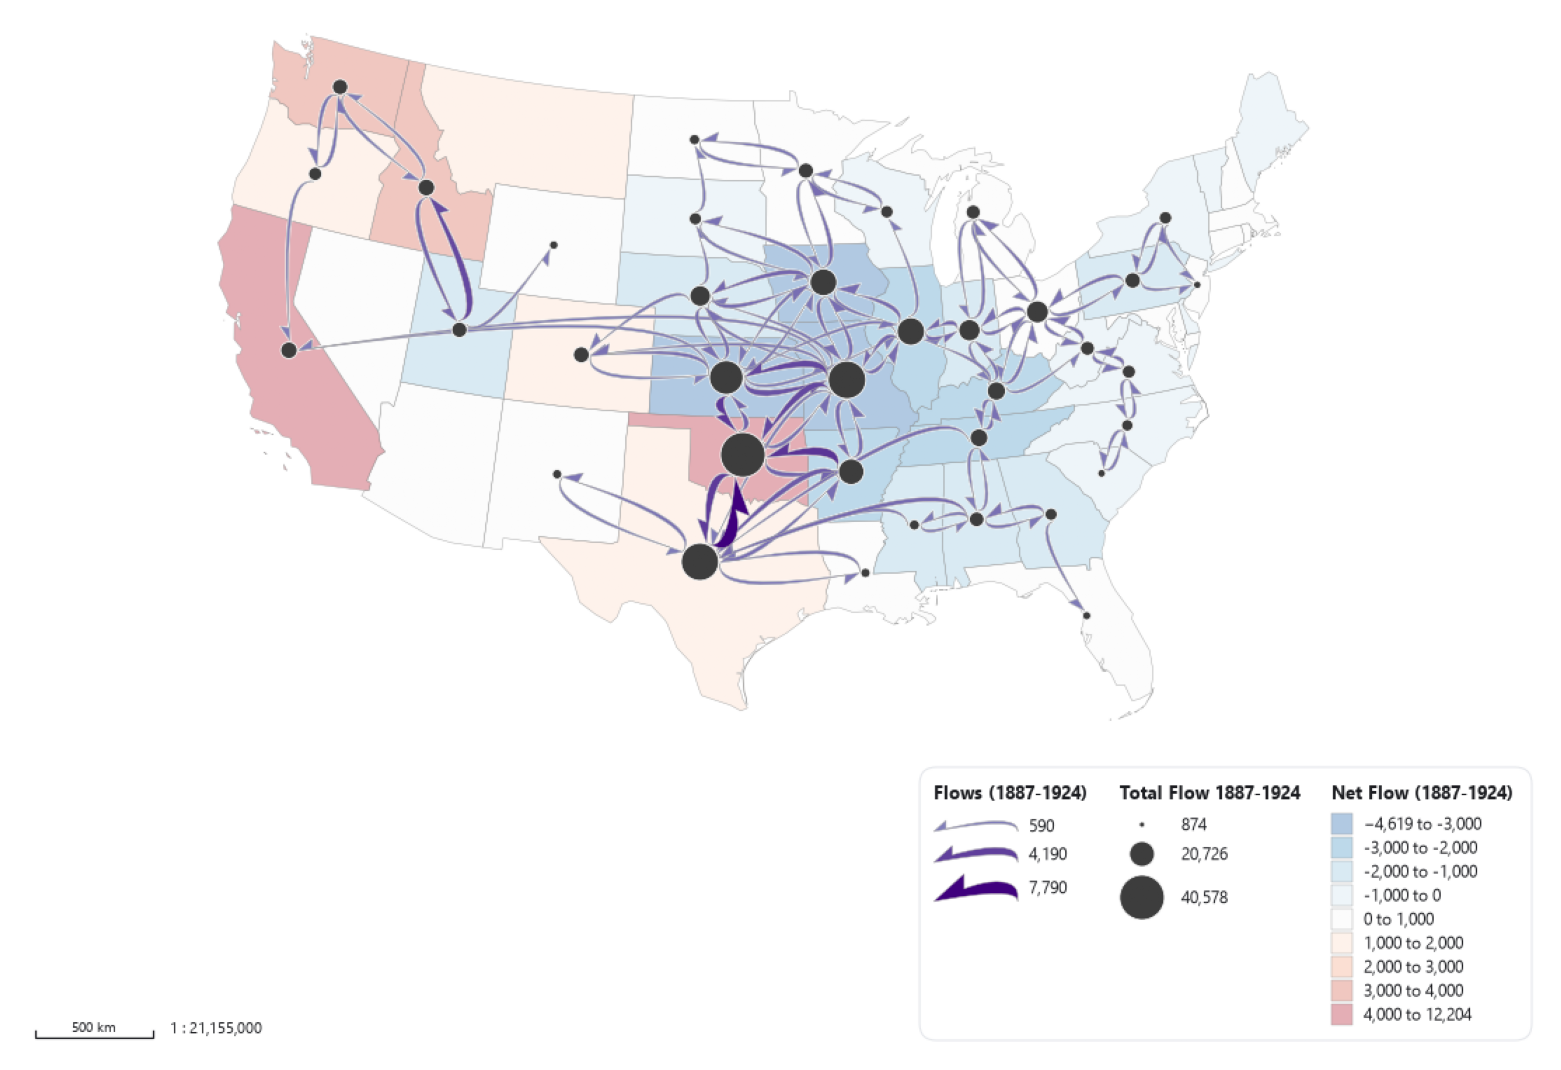

In [7]:
F = DATA / "FamilyTree"
fam = fm.Project.from_data(F / "nodes_states_1789_1924.csv", F / "flows_1887_1924.csv",
                           regions=F / "regions_states_latlon(base map input).json",
                           region_table=F / "nodes_states_1789_1924.csv", name="Family trees 1887-1924")
family_recipe = {
    "region_join": {"geoId": "rootsid", "CSVId": "rootsid", "value": "Netflow_1887_1924"},
    "region_settings": {"ifMapRegionAttribute": True, "cfMethod": "ManualBreak", "clrScheme": "RdBu", "ifFlipColor": True,
                        "clsNum": 9, "breakInput": "-4619 -3000 -2000 -1000 0 1000 2000 3000 4000 12204",
                        "fillOpacity": 60, "strokeColor": "Black", "legendTitle": "Net Flow (1887-1924)"},
    "node_settings": {"id": "rootsid", "X": "x", "Y": "y", "ifMapAttribute": True, "volume": "TotalFlow_1887_1924",
                      "strokeColor": "#dedede", "strokeWidth": 1, "legendTitle": "Total Flow 1887-1924"},
    "flow_settings": {"origin": "orgState", "destination": "destState", "volume": "flows",
                      "flowStyleName": "CHA", "clrScheme": "Custom", "breakInput": "500 1000 2000 4000",
                      "widthMax": 18, "strokeColor": "#ababab", "legendTitle": "Flows (1887-1924)"},
}
apply_recipe(fam, family_recipe)

fam_hc = figure_ground(fam.copy(), flows="purple")
fam_hc.flow_settings["flowStyleName"] = "CHA"
size_nodes_by_total_flow(fam_hc, title="Total Flow 1887-1924")
final_map(fam_hc, LOWER48, height=750)

## Save the recipes as FlowMapper.org projects

Every rebuilt project can be opened, edited and shared on FlowMapper.org.

In [8]:
maps = {"ukraine_2022": (ukr_hc, EUROPE), "katrina_2005_06": (kat_hc, LOWER48),
        "syria_2024": (syr_hc, (-12, 24, 60, 64)), "bananas_2019": (ban_hc, (-82, -56, -34, 13)),
        "family_1887_1924": (fam_hc, LOWER48)}
for name, (p, extent) in maps.items():
    p.save(OUT / f"recipe_{name}.json")
    p.save_map(OUT / f"recipe_{name}.png", width=1100, height=800, dpi=144, extent=extent, **CONTRAST)
print(sorted(f.name for f in OUT.glob("recipe_*")))

['recipe_bananas_2019.json', 'recipe_bananas_2019.png', 'recipe_family_1887_1924.json', 'recipe_family_1887_1924.png', 'recipe_katrina_2005_06.json', 'recipe_katrina_2005_06.png', 'recipe_syria_2024.json', 'recipe_syria_2024.png', 'recipe_ukraine_2022.json', 'recipe_ukraine_2022.png']
